# 🧮 Gaussian Naive Bayes from Scratch

**Goal:** Classify data by applying Bayes' theorem and assuming features are conditionally independent given the class.

---

## 1. Algorithm Intuition

**Bayes' theorem:**
$$P(y \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid y) \cdot P(y)}{P(\mathbf{x})}$$

**Naive assumption:** Features are **conditionally independent** given the class label. This makes the likelihood factorize:

$$P(\mathbf{x} \mid y) = \prod_{j=1}^{n} P(x_j \mid y)$$

**Gaussian assumption:** Each per-feature conditional distribution is Gaussian:

$$P(x_j \mid y = c) = \frac{1}{\sqrt{2\pi\sigma_{cj}^2}} \exp\!\left(-\frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2}\right)$$

**Prediction** (we drop $P(\mathbf{x})$ since it is constant across classes):

$$\hat{y} = \arg\max_{c} \left[ \log P(y=c) + \sum_{j=1}^{n} \log P(x_j \mid y=c) \right]$$

We work in **log-space** to avoid numerical underflow from multiplying many small probabilities.

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $c$ | class label |
| $\mu_{cj}$ | mean of feature $j$ for class $c$ |
| $\sigma_{cj}^2$ | variance of feature $j$ for class $c$ |
| $P(y=c)$ | prior probability of class $c$ |
| $P(x_j \mid y=c)$ | Gaussian likelihood of feature $j$ given class $c$ |


## 2. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(3)
plt.style.use('seaborn-v0_8-whitegrid')

## 3. Synthetic Data — 3-Class Problem

In [2]:
def make_blobs(n_per_class, centers, stds, seed=3):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []
    for label, (cx, cy) in enumerate(centers):
        std = stds[label]
        pts = rng.normal(loc=[cx, cy], scale=std, size=(n_per_class, 2))
        X_list.append(pts)
        y_list.append(np.full(n_per_class, label))
    X = np.vstack(X_list)
    y = np.hstack(y_list)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

centers = [(-3, -2), (0, 4), (4, -1)]
stds    = [0.9, 1.1, 0.8]
X_all, y_all = make_blobs(n_per_class=120, centers=centers, stds=stds)

print(f"X shape: {X_all.shape}, y shape: {y_all.shape}")

X shape: (360, 2), y shape: (360,)


## 4. Train / Test Split

In [3]:
def train_test_split(X, y, test_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    s = int(len(y) * (1 - test_ratio))
    return X[idx[:s]], X[idx[s:]], y[idx[:s]], y[idx[s:]]

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (288, 2), Test: (72, 2)


## 5. Fitting — Compute Per-Class Statistics

The "training" phase for Gaussian Naive Bayes is simply computing the **prior** and the **mean + variance** of each feature within each class.

In [4]:
def fit_gnb(X_train, y_train):
    """
    Fit Gaussian Naive Bayes on training data.

    Returns
    -------
    classes   : ndarray  — unique class labels
    log_priors: ndarray  — log P(y=c) for each class c
    mu        : ndarray (n_classes, n_features) — per-class feature means
    var       : ndarray (n_classes, n_features) — per-class feature variances
    """
    classes    = np.unique(y_train)
    n_classes  = len(classes)
    n_features = X_train.shape[1]
    m          = X_train.shape[0]

    mu         = np.zeros((n_classes, n_features))
    var        = np.zeros((n_classes, n_features))
    log_priors = np.zeros(n_classes)

    for i, c in enumerate(classes):
        X_c = X_train[y_train == c]       # rows belonging to class c
        mu[i]  = X_c.mean(axis=0)
        var[i] = X_c.var(axis=0)          # MLE variance
        log_priors[i] = np.log(X_c.shape[0] / m)

        print(f"Class {c}: n={X_c.shape[0]}, prior={np.exp(log_priors[i]):.3f}")

    return classes, log_priors, mu, var

classes, log_priors, mu, var = fit_gnb(X_train, y_train)

Class 0: n=96, prior=0.333
Class 1: n=98, prior=0.340
Class 2: n=94, prior=0.326


## 6. Gaussian Log-Likelihood

In [5]:
def log_gaussian(x, mean, variance):
    """
    Log of Gaussian PDF: log N(x; mean, variance).

    log P(x | mean, var) = -0.5 * log(2 * pi * var)  -  (x - mean)^2 / (2 * var)

    A small epsilon is added to variance to prevent log(0).
    """
    eps = 1e-10
    return -0.5 * np.log(2 * np.pi * (variance + eps)) \
           - ((x - mean) ** 2) / (2 * (variance + eps))

## 7. Prediction

In [6]:
def predict_gnb(X, classes, log_priors, mu, var):
    """
    Predict class labels for each row of X.

    For each sample x and class c:
      log_posterior(c) = log_prior(c) + sum_j log_gaussian(x_j; mu_cj, var_cj)

    Predicted class = argmax over c of log_posterior(c).
    """
    n_classes = len(classes)
    log_posteriors = np.zeros((X.shape[0], n_classes))

    for i in range(n_classes):
        # Sum log-likelihoods over all features for class i
        # log_gaussian returns (m, n) array; sum across features → (m,)
        log_likelihood = np.sum(log_gaussian(X, mu[i], var[i]), axis=1)
        log_posteriors[:, i] = log_priors[i] + log_likelihood

    best_class_idx = np.argmax(log_posteriors, axis=1)
    return classes[best_class_idx]

In [7]:
y_pred_test = predict_gnb(X_test, classes, log_priors, mu, var)
print(f"Predictions  (first 15): {y_pred_test[:15].astype(int)}")
print(f"Ground truth (first 15): {y_test[:15].astype(int)}")

Predictions  (first 15): [2 0 2 1 0 0 1 1 1 0 1 2 1 0 2]
Ground truth (first 15): [2 0 2 1 0 0 1 1 1 0 1 2 1 0 2]


## 8. Decision Boundary Visualisation

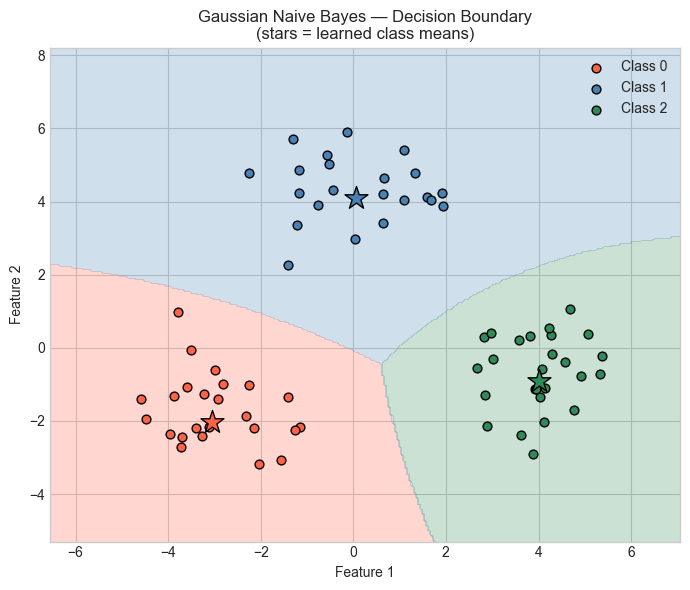

In [8]:
palette = ['tomato', 'steelblue', 'seagreen']

x1_min, x1_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
x2_min, x2_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                     np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
grid_preds = predict_gnb(grid, classes, log_priors, mu, var)
grid_preds = grid_preds.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(xx, yy, grid_preds,
            levels=[-0.5, 0.5, 1.5, 2.5],
            colors=palette, alpha=0.25)
for cls in range(3):
    mask = y_test.astype(int) == cls
    ax.scatter(X_test[mask, 0], X_test[mask, 1],
               color=palette[cls], edgecolors='k', s=40, label=f'Class {cls}')
# Mark class centroids
for i, c in enumerate(classes):
    ax.scatter(mu[i, 0], mu[i, 1], marker='*', s=300,
               color=palette[i], edgecolors='black', zorder=5)
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_title('Gaussian Naive Bayes — Decision Boundary\n(stars = learned class means)')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Visualise Learned Gaussian Distributions (Feature 0)

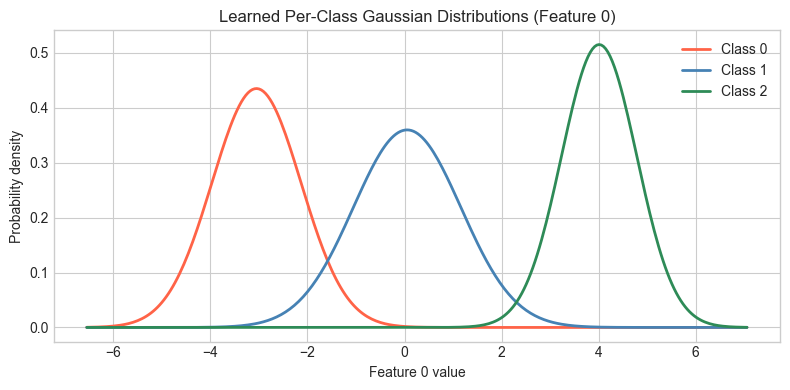

In [9]:
x_range = np.linspace(X_all[:, 0].min() - 1, X_all[:, 0].max() + 1, 300)

fig, ax = plt.subplots(figsize=(8, 4))
for i, c in enumerate(classes):
    # Gaussian PDF from learned parameters
    pdf = (1 / np.sqrt(2 * np.pi * var[i, 0])) * \
          np.exp(-0.5 * (x_range - mu[i, 0]) ** 2 / var[i, 0])
    ax.plot(x_range, pdf, color=palette[i], linewidth=2, label=f'Class {int(c)}')

ax.set_xlabel('Feature 0 value')
ax.set_ylabel('Probability density')
ax.set_title('Learned Per-Class Gaussian Distributions (Feature 0)')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Evaluation Metrics

In [10]:
def accuracy(y_true, y_pred):
    return np.mean(y_true.astype(int) == y_pred.astype(int))

def multiclass_confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true.astype(int), y_pred.astype(int)):
        cm[t][p] += 1
    return cm

y_pred_train = predict_gnb(X_train, classes, log_priors, mu, var)
print(f"Train Accuracy: {accuracy(y_train, y_pred_train):.4f}")
print(f"Test  Accuracy: {accuracy(y_test,  y_pred_test):.4f}")

cm = multiclass_confusion_matrix(y_test, y_pred_test, n_classes=3)
print("\nConfusion Matrix (rows=actual, cols=predicted):")
print('           ' + '  '.join([f'Pred {c}' for c in range(3)]))
for i, row in enumerate(cm):
    print(f"Actual {i}    " + '  '.join([f'{v:6d}' for v in row]))

Train Accuracy: 1.0000
Test  Accuracy: 1.0000

Confusion Matrix (rows=actual, cols=predicted):
           Pred 0  Pred 1  Pred 2
Actual 0        24       0       0
Actual 1         0      22       0
Actual 2         0       0      26


## 11. Observations and Limitations

### What we observed
- GNB is extremely fast to train — it only computes means, variances, and priors.
- The decision boundary is a quadratic curve (not a straight line) because each class has its own covariance.
- High accuracy when class distributions are approximately Gaussian and not too overlapping.

### Limitations
| Limitation | Description |
|------------|-------------|
| **Naive independence assumption** | Real features are often correlated; violating independence can degrade accuracy. |
| **Gaussian assumption** | Works poorly if features are multi-modal or have heavy tails. |
| **Zero-frequency problem** | If a feature value never appeared for some class in training, its likelihood is 0 — fix with Laplace smoothing (less relevant for continuous features). |
| **Calibration** | Outputs are posterior probabilities but may be poorly calibrated. |
